In [1]:
!pip install prophet

   ---------------------------------------- 0.0/12.1 MB ? eta -:--:--
   ------ --------------------------------- 1.8/12.1 MB 12.9 MB/s eta 0:00:01
   ------------ --------------------------- 3.7/12.1 MB 10.9 MB/s eta 0:00:01
   ----------------- ---------------------- 5.2/12.1 MB 10.0 MB/s eta 0:00:01
   -------------------- ------------------- 6.3/12.1 MB 8.5 MB/s eta 0:00:01
   ---------------------- ----------------- 6.8/12.1 MB 6.9 MB/s eta 0:00:01
   ----------------------- ---------------- 7.1/12.1 MB 6.3 MB/s eta 0:00:01
   ------------------------- -------------- 7.6/12.1 MB 5.6 MB/s eta 0:00:01
   ------------------------- -------------- 7.6/12.1 MB 5.6 MB/s eta 0:00:01
   -------------------------- ------------- 8.1/12.1 MB 4.4 MB/s eta 0:00:01
   --------------------------- ------------ 8.4/12.1 MB 4.2 MB/s eta 0:00:01
   ---------------------------- ----------- 8.7/12.1 MB 3.9 MB/s eta 0:00:01
   ---------------------------- ----------- 8.7/12.1 MB 3.9 MB/s eta 0:00:01
   


[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from prophet import Prophet
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [3]:
data = {
    "ds": pd.date_range("2023-01-01", periods=36, freq="MS"),
    "y": [
        120, 125, 138, 145, 155, 165, 172, 168, 158, 150, 140, 155,
        132, 138, 150, 160, 174, 183, 190, 185, 174, 165, 154, 171,
        148, 154, 168, 179, 193, 203, 210, 205, 194, 184, 173, 191
    ]
}

df = pd.DataFrame(data)

print(df.head())
print(df.tail())

          ds    y
0 2023-01-01  120
1 2023-02-01  125
2 2023-03-01  138
3 2023-04-01  145
4 2023-05-01  155
           ds    y
31 2025-08-01  205
32 2025-09-01  194
33 2025-10-01  184
34 2025-11-01  173
35 2025-12-01  191


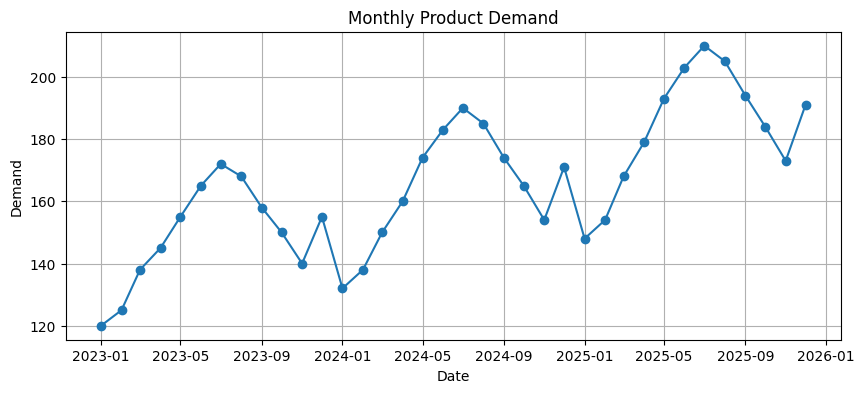

In [4]:
plt.figure(figsize=(10, 4))

plt.plot(df["ds"], df["y"], marker="o")

plt.title("Monthly Product Demand")
plt.xlabel("Date")
plt.ylabel("Demand")

plt.grid(True)
plt.show()

In [5]:
train = df.iloc[:-6].copy()
test = df.iloc[-6:].copy()

print("Training observations:", len(train))
print("Testing observations:", len(test))

Training observations: 30
Testing observations: 6


In [7]:
model = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=False,
    daily_seasonality=False
)

model.fit(train)

16:02:36 - cmdstanpy - INFO - Chain [1] start processing
16:03:12 - cmdstanpy - INFO - Chain [1] done processing


In [8]:
future = model.make_future_dataframe(
    periods=6,
    freq="MS",
    include_history=True
)

forecast = model.predict(future)

predictions = forecast[
    ["ds", "yhat", "yhat_lower", "yhat_upper"]
].tail(6)

print("Forecast Results:")
print(predictions)

Forecast Results:
           ds        yhat  yhat_lower  yhat_upper
30 2025-07-01  210.934249  210.520860  211.396873
31 2025-08-01  206.792989  205.462845  208.264130
32 2025-09-01  196.596711  193.974404  199.301241
33 2025-10-01  188.624014  184.504891  192.921215
34 2025-11-01  178.809337  172.758589  185.163328
35 2025-12-01  195.625625  187.474531  203.971014


In [9]:
comparison = test.merge(predictions, on="ds")

print("Actual vs Predicted Demand:")
print(comparison)

Actual vs Predicted Demand:
          ds    y        yhat  yhat_lower  yhat_upper
0 2025-07-01  210  210.934249  210.520860  211.396873
1 2025-08-01  205  206.792989  205.462845  208.264130
2 2025-09-01  194  196.596711  193.974404  199.301241
3 2025-10-01  184  188.624014  184.504891  192.921215
4 2025-11-01  173  178.809337  172.758589  185.163328
5 2025-12-01  191  195.625625  187.474531  203.971014


In [10]:
y_true = comparison["y"].values
y_pred = comparison["yhat"].values

mae = mean_absolute_error(y_true, y_pred)

rmse = np.sqrt(
    mean_squared_error(y_true, y_pred)
)

mape = np.mean(
    np.abs((y_true - y_pred) / y_true)
) * 100

print("MAE :", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("MAPE:", round(mape, 2), "%")

MAE : 3.4
RMSE: 3.82
MAPE: 1.83 %


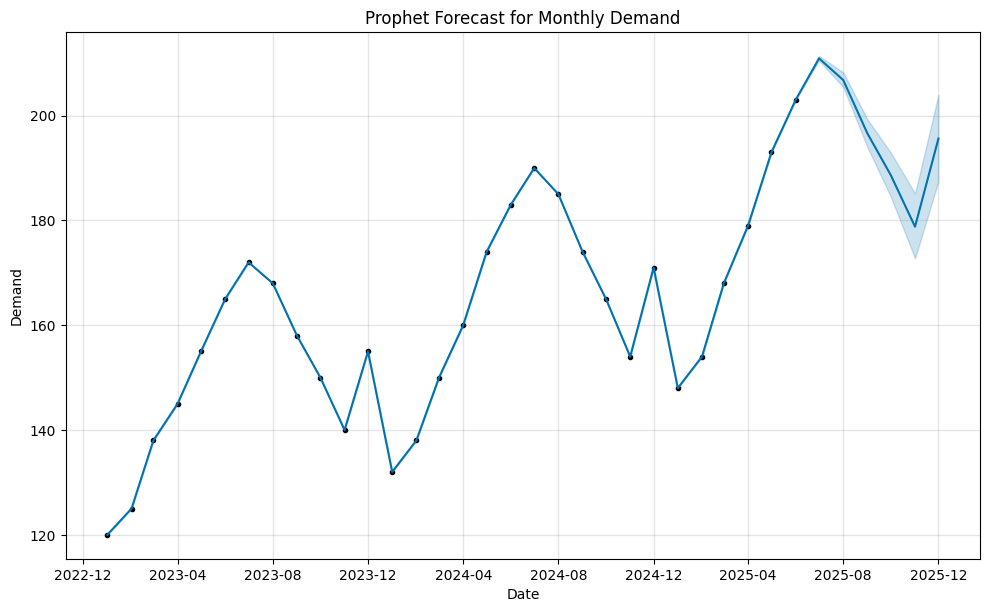

In [11]:
fig1 = model.plot(forecast)

plt.title("Prophet Forecast for Monthly Demand")
plt.xlabel("Date")
plt.ylabel("Demand")

plt.show()

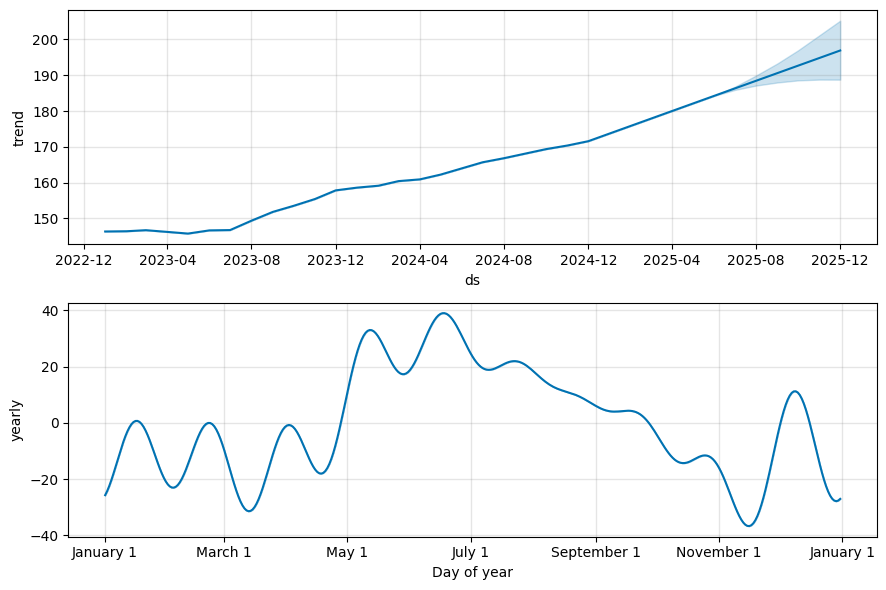

In [12]:
fig2 = model.plot_components(forecast)

plt.show()